# Quick look

A tour of the ATLAST analysis path: load a photometry file, apply quality cuts,
inspect which chip each epoch came from, bin to one point per night, check and remove
the baseline flux, and export to SNANA format.

The example is **SN 2022wpy**, a well-observed normal Type Ia at *z* = 0.0154. A copy
of its forced photometry ships alongside this notebook, so it runs as-is.

## Getting the photometry file

The file used below was downloaded from the ATLAS forced photometry server. To obtain
exactly the same data yourself, query these coordinates and dates (see the
[querying guide](../rst_files/querying.rst) for tokens and polling):

| | |
|---|---|
| Object | SN 2022wpy (Type Ia, *z*<sub>hel</sub> = 0.01542) |
| RA | 71.616798 deg |
| Dec | −4.789900 deg |
| MJD range | 59777 – 60214 |
| Peak (SALT2) | MJD 59871.05 |
| Milky Way E(B−V) | 0.0314 |

```python
from atlast import QueryATLAS

api = QueryATLAS(api_token='your_api_token_here')

task_url = api.request_phot(
    ra=71.616798,
    dec=-4.789900,
    mjd_min=59777,
    mjd_max=60214,
    use_reduced=False,
)

# once the server has finished the job
phot_file = api.save_phot(task_url, folder='phot_output')
```

Any ATLAS forced photometry file works here — point `phot_file` at your own to follow
along with a different object.

In [1]:
%matplotlib inline
import os
import tempfile
import warnings

import numpy as np
import matplotlib.pyplot as plt

# astropy 8 emits a deprecation warning on import that has nothing to do with us
warnings.filterwarnings('ignore', message='.*TestRunner.*')

phot_file = os.path.join('data', '2022wpy.txt')
objname = '2022wpy'

pkmjd_salt2 = 59871.05          # published SALT2 peak, used for the baseline window
redshift = 0.01542
mwebv = 0.0314                  # Milky Way E(B-V) toward this line of sight

## Loading

`AtlasPhotometry` parses the file, converts microJansky to the SNANA flux scale,
identifies the chip behind every epoch, and applies a default cut.

In [2]:
from atlast import AtlasPhotometry

phot = AtlasPhotometry(phot_file, objname=objname)

print(f'epochs in file      : {len(phot._mjd)}')
print(f'epochs passing cuts : {len(phot.mjd)}')
print(f'MJD range           : {phot._mjd.min():.1f} to {phot._mjd.max():.1f}')
print(f'filters             : {np.unique(phot._filters)}')

epochs in file      : 662
epochs passing cuts : 662
MJD range           : 59777.2 to 60213.3
filters             : ['c' 'o']


No template-change warning appeared, so this light curve sits entirely within one
reference epoch. A light curve spanning MJD 58417 or 58882 would print a warning here
— see [systematics and corrections](../rst_files/corrections.rst).

Note the two sets of arrays. Underscore-prefixed (`_mjd`, `_flux`, ...) always hold
every row in the file; the bare names (`mjd`, `flux`, ...) hold only what passes the
current cuts, with `phot.cuts` as the mask between them.

`phot.df_phot` is the raw dataframe the file was read into:

In [3]:
phot.df_phot[['MJD', 'm', 'dm', 'uJy', 'duJy', 'F', 'chi/N', 'Obs']].head()

,MJD,m,dm,uJy,duJy,F,chi/N,Obs
0,59777.159706,-21.993,5.318,-6,31,o,1.04,03a59777o1025o
1,59777.163865,19.537,0.627,56,35,o,1.08,03a59777o1034o
2,59777.177519,-21.954,6.773,-6,41,o,1.18,03a59777o1064o
3,59777.184326,-19.232,0.935,-74,69,o,1.16,03a59777o1079o
4,59800.590288,-20.558,0.537,-22,12,o,1.25,02a59800o0756o


2 of 662 epochs lie outside the plotted range
most extreme flux: -633,087 FLUXCAL


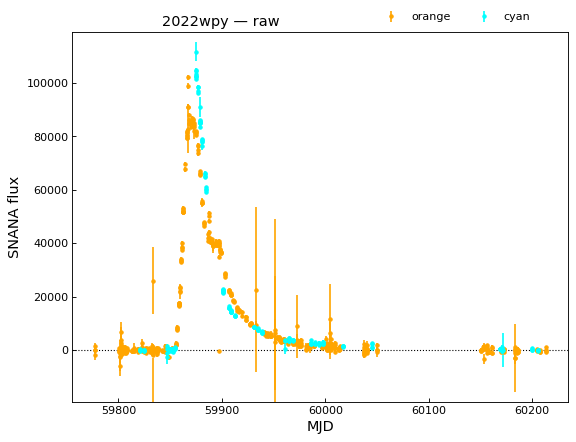

In [4]:
fig, ax = phot.plot_lc(title=f'{objname} — raw')

# a few bad subtractions sit thousands of sigma away and would squash the plot,
# so clip the view to the bulk of the data
lo, hi = np.percentile(phot.flux, [0.5, 99.5])
pad = 0.15 * (hi - lo)
ax.set_ylim(lo - pad, hi + pad)

n_off = ((phot.flux < lo - pad) | (phot.flux > hi + pad)).sum()
print(f'{n_off} of {len(phot.mjd)} epochs lie outside the plotted range')
print(f'most extreme flux: {phot.flux.min():,.0f} FLUXCAL')

That single epoch at roughly -630,000 FLUXCAL is a catastrophically bad subtraction —
about 7x the supernova's peak flux, in the negative direction. Removing this kind of
epoch is what the quality cuts below are for.

## Quality cuts

`cut()` recomputes the mask from the **full** dataset every time, so cuts do not
accumulate unless you pass the current mask in with `s=`.

In [5]:
phot.cut(fluxerr_max=3000)
print(f'fluxerr cut only            : {len(phot.mjd)}')

phot.cut(chi2dof_max=5)
print(f'chi2 cut only  (restarted!) : {len(phot.mjd)}')

phot.cut(s=phot.cuts, fluxerr_max=3000)
print(f'both, chained with s=       : {len(phot.mjd)}')

fluxerr cut only            : 641
chi2 cut only  (restarted!) : 610
both, chained with s=       : 589


## Which chip took each epoch?

The first three characters of the `Obs` column give the *sitecam*; combined with the
MJD, that identifies a unique detector via the packaged chip table. The chip ID is the
row index of `df_chip`.

In [6]:
from atlast import df_chip

display(df_chip)

ids, counts = np.unique(phot._chipid[np.isfinite(phot._chipid)], return_counts=True)
for i, n in zip(ids, counts):
    row = df_chip.loc[int(i)]
    print(f'chip {int(i)}: {row.sitecam} {row.chip_nickname:<18} {n:4d} epochs')

print(f'\nunidentified chip: {np.isnan(phot._chipid).sum()} epochs (always dropped by cut())')

,sitecam,chip_nickname,mjd_min,mjd_max
0,01a,acam2,57800.123622,58715.64170035
1,01a,gold,58719.353907,59465.63979805
2,01a,green+fuzzy+4x,59466.018577,59830.64425335
3,01a,magenta+wormy+5x,59830.644253,999999
4,02a,acam1,57800.123883,58717.64234705
5,02a,red,58718.169868,59519.65651365
6,02a,red+alien+1,59522.125799,999999
7,03a,blue+cruddy+2,59561.864492,999999
8,04a,gold+freckles+3x,59605.030665,999999


chip 2: 01a green+fuzzy+4x       24 epochs
chip 3: 01a magenta+wormy+5x     82 epochs
chip 6: 02a red+alien+1         102 epochs
chip 7: 03a blue+cruddy+2       216 epochs
chip 8: 04a gold+freckles+3x    238 epochs

unidentified chip: 0 epochs (always dropped by cut())


This object was observed from all four ATLAS sites, on five different detectors. Any
chip-to-chip zero-point difference therefore enters as scatter in the combined light
curve, which is what `apply_flux_corr` exists to remove.

The zero-point maps it needs — and the error fudge function used by
`apply_fudge_func` — are TITAN-team calibration products and are **not distributed
with ATLAST**. See [Marlin et al.](https://arxiv.org/abs/2512.21903)
(arXiv:2512.21903) for how they are derived, and contact Y. S. Murakami or Eli Marlin
to request access; they are reserved for the TITAN team until the science analyses are
complete.

Epochs matching no row get `_chipid = nan` and are removed by every `cut()` call. A
light curve losing an unexpected number of epochs here usually means `chip_info.dat`
needs a new row.

## Intraday outliers

The cuts above judge each epoch on its own — formal error, PSF chi-square. They cannot
catch an epoch that looks reasonable in isolation but disagrees with the other
exposures taken the *same night*.

ATLAS visits a field several times per night, so every exposure has siblings to be
compared against. `calc_nightly_pull` groups exposures within `delta_mjd`, computes a
sigma-clipped inverse-variance weighted mean per night and filter, and records each
epoch's **pull**:

$$\mathrm{pull} = \frac{f - \bar{f}_\mathrm{night}}{\sigma_f}$$

A well-behaved exposure has a pull of order 1.

In [7]:
phot.cut(fluxerr_max=3000, chi2dof_max=5)
phot.calc_nightly_pull(delta_mjd=0.5, pull_clip=3)

pull = phot._flux_pull[np.isfinite(phot._flux_pull)]
print(f'median |pull| : {np.median(np.abs(pull)):.2f}')
print(f'max    |pull| : {np.max(np.abs(pull)):.1f}')
for t in (3, 5, 10):
    print(f'  |pull| > {t:2d} : {(np.abs(pull) > t).sum():3d} epochs')

median |pull| : 0.61
max    |pull| : 103.5
  |pull| >  3 :   6 epochs
  |pull| >  5 :   2 epochs
  |pull| > 10 :   1 epochs


The median epoch sits well within 1 sigma of its own night, but a
tail runs out past 70 sigma — those are the intraday outliers. Cut on them with
`flux_pull_max`. A threshold of 5 is a reasonable default: loose enough to leave
ordinary scatter alone, tight enough to catch a genuinely discrepant exposure.

589 -> 585 epochs  (4 cut on pull)


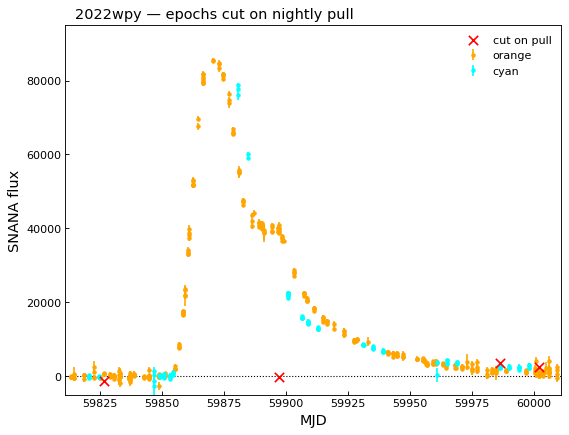

In [8]:
quality_only = phot.cuts.copy()
phot.cut(s=quality_only, flux_pull_max=5)

removed = quality_only & ~phot.cuts
print(f'{quality_only.sum()} -> {phot.cuts.sum()} epochs  ({removed.sum()} cut on pull)')

fig, ax = phot.plot_lc(title=f'{objname} — epochs cut on nightly pull')
ax.scatter(phot._mjd[removed], phot._flux[removed],
           marker='x', color='red', s=70, zorder=20, label='cut on pull')
ax.set_xlim(pkmjd_salt2 - 60, pkmjd_salt2 + 140)
ax.set_ylim(-5000, 95000)
_ = ax.legend(frameon=False, loc='upper right')

All four are isolated bad subtractions that the error and
chi-square cuts let through. The worst reads −220 FLUXCAL with a formal error of 386,
on a night where the other nine orange exposures agree on ≈39,900 — a pull of −104.

Two of the four fail the `flux_pull_max=5` threshold outright. The other two fail the
second half of the cut: `flux_pull_max` also drops any epoch that was excluded when its
night's weighted mean was computed, recorded in `_pull_clip`.

That reference mean is computed robustly — seeded from the median and clipped on the
normalized MAD of the pulls — so a single low-error outlier cannot drag the value its
siblings are being compared against.

## Binning

ATLAS takes several exposures per visit. Combining them with an inverse-variance
weighted mean is worth roughly a factor of two in signal-to-noise.

585 epochs -> 135 nightly points


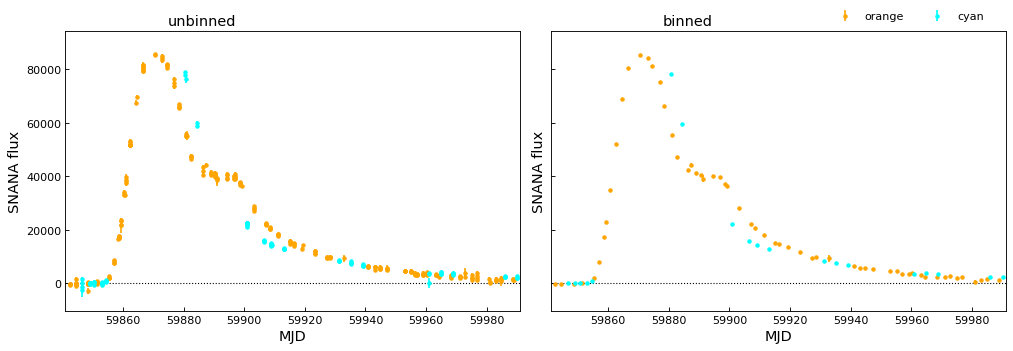

In [9]:
lc = phot.group_by_mjd(delta_mjd=0.5)

print(f'{len(phot.mjd)} epochs -> {len(lc.mjd)} nightly points')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
phot.plot_lc(ax=axes[0], title='unbinned', legend=False)
lc.plot_lc(ax=axes[1], title='binned')

# zoom on the transient -- the full 436-day window is mostly baseline
for ax in axes:
    ax.set_xlim(pkmjd_salt2 - 30, pkmjd_salt2 + 120)
plt.tight_layout()

The binned peak should land close to the published SALT2 peak time:

In [10]:
pkmjd = lc.mjd[np.argmax(lc.flux)]
print(f'brightest nightly point : MJD {pkmjd:.2f}')
print(f'published SALT2 peak    : MJD {pkmjd_salt2:.2f}')

brightest nightly point : MJD 59870.60
published SALT2 peak    : MJD 59871.05


## Checking the baseline

Long before and long after the transient, the true flux is zero — so anything measured
there is contamination, usually from the supernova itself appearing in the reference
image. `get_zero_levels` sigma-clips those epochs and combines them with an
inverse-variance weighted mean.

In [11]:
zero_levels = lc.get_zero_levels(pkmjd=pkmjd_salt2, phase_before=-40, phase_after=200)

for filt, (level, level_err) in zero_levels.items():
    sigma = level / level_err if level_err else np.nan
    print(f'{filt}: {level:8.2f} +/- {level_err:5.2f} FLUXCAL  ({sigma:+.1f} sigma from zero)')

o:   -92.57 +/- 47.95 FLUXCAL  (-1.9 sigma from zero)
c:     4.54 +/- 63.80 FLUXCAL  (+0.1 sigma from zero)


The cyan baseline is consistent with zero. The orange one sits about 2.4 sigma low,
a small residual over-subtraction of roughly 0.1% of peak flux — worth subtracting, but
not a sign of a problem. Applying the correction also propagates each offset's
uncertainty into the flux errors.

Always check the values before applying them: a filter with too few baseline epochs
comes back as `[0, 0]`, and a filter with any zero-valued error comes back as `nan`.

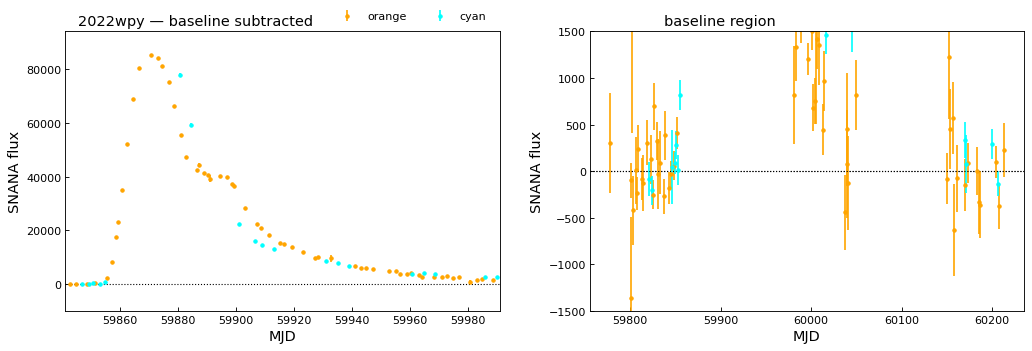

In [12]:
assert all(np.isfinite(v[0]) for v in zero_levels.values()), zero_levels

lc.subtract_flux_offset(zf_t3=zero_levels)   # zf_t3 = the current template era

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

lc.plot_lc(ax=axes[0], title=f'{objname} — baseline subtracted')
axes[0].set_xlim(pkmjd_salt2 - 30, pkmjd_salt2 + 120)

# same data, zoomed hard on zero to show the baseline itself
lc.plot_lc(ax=axes[1], title='baseline region', legend=False)
axes[1].set_ylim(-1500, 1500)
axes[1].axhline(0, c='k', ls=':', lw=1)
plt.tight_layout()

The uncertainty on each offset is added to the flux errors in quadrature, and the
uncorrected arrays are cached in `_flux_raw`, so the call can safely be repeated with
different offsets.

## Exporting to SNANA

Because ATLAST already works in the SNANA `FLUXCAL` scale, export is pure formatting.
Note that export needs chip IDs, so it runs on the **unbinned** object.

In [13]:
snana_file = os.path.join(tempfile.mkdtemp(), f'{objname}.snana.txt')

phot.to_SNANA(snana_file, header={
    'SURVEY': 'ATLAS',
    'SNID': objname,
    'RA': '71.61680',
    'DECL': '-4.78990',
    'REDSHIFT_HELIO': f'{redshift:.5f} +- 0.0001',
    'MWEBV': '0.0314',
    'FILTERS': 'co',
})

print(''.join(open(snana_file).readlines()[:12]))

SURVEY: ATLAS
SNID: 2022wpy
RA: 71.61680
DECL: -4.78990
REDSHIFT_HELIO: 0.01542 +- 0.0001
MWEBV: 0.0314
FILTERS: co

# ========================================
NOBS: 585
NVAR: 5
VARLIST: MJD FLT FIELD FLUXCAL FLUXCALERR



The filter names are `ATLAS-o8`, `ATLAS-c7` and so on: filter plus chip ID. That lets
a downstream SNANA fit solve for a separate zero point per chip — useful here, since
this object was observed on five of them. Pass a `filtername_map` to `to_SNANA` if you
would rather collapse them back to `o` and `c`.

Reading the file back gives a `SNANAPhotometry`, which is an `AtlasPhotometry`
subclass and so supports the same cuts, plotting and fitting:

metadata : {'SURVEY': 'ATLAS', 'SNID': '2022wpy', 'RA': '71.61680', 'DECL': '-4.78990', 'REDSHIFT_HELIO': '0.01542 +- 0.0001', 'MWEBV': '0.0314', 'FILTERS': 'co', 'NOBS': 585, 'NVAR': '5'}
epochs   : 585


(-5000.0, 95000.0)

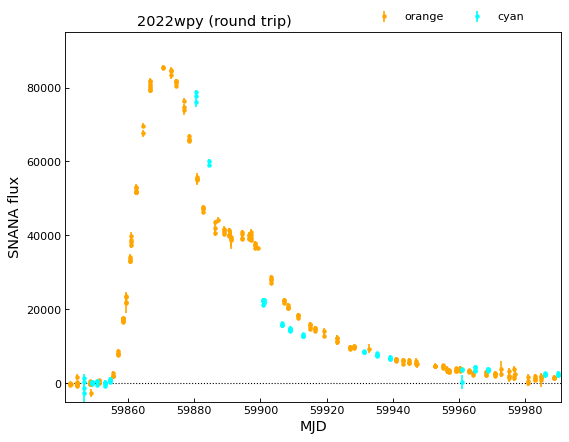

In [14]:
from atlast import SNANAPhotometry

fmap = {f'ATLAS-{f}{i}': f for f in 'co' for i in range(len(df_chip))}
sn = SNANAPhotometry(snana_file, objname=f'{objname} (round trip)', filtername_map=fmap)

print(f'metadata : {sn.metadata}')
print(f'epochs   : {len(sn.mjd)}')

fig, ax = sn.plot_lc()
ax.set_xlim(pkmjd_salt2 - 30, pkmjd_salt2 + 120)
ax.set_ylim(-5000, 95000)

## Fitting

Fitting uses [SNCosmo](https://sncosmo.readthedocs.io), an optional dependency. The
ATLAS bandpasses have to be registered once per session before any fit — the
transmission curves ship with the package, so nothing needs downloading.

Adding ATLAS filters to SNCosmo... Done


fit succeeded: True


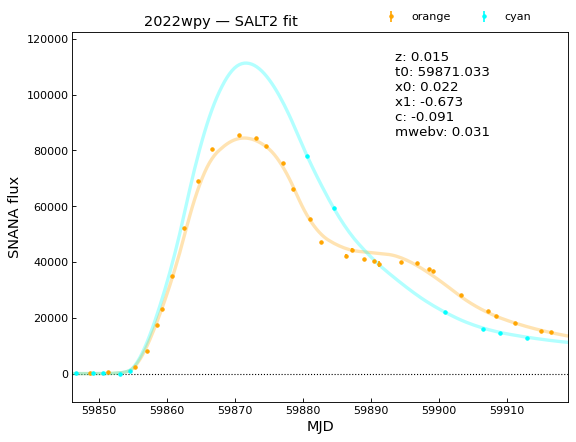

In [15]:
from atlast import init_sncosmo_filters

init_sncosmo_filters()          # registers 'o' and 'c' with SNCosmo

lc.set_sncosmo_redshift_bounds((0.005, 0.05))

fig, ax = lc.plot_lc(title=f'{objname} — SALT2 fit')

# SALT2 only covers about -20 to +50 rest-frame days; outside that its bandflux
# returns zero, so keep the plotted range inside the model's validity
ax.set_xlim(pkmjd_salt2 - 25, pkmjd_salt2 + 48)

ok = lc.fit_lc(
    preset_vals={'z': redshift, 'mwebv': mwebv},   # both known, so hold them fixed
    modelcov=True,
    plot=True,
    ax=ax,
    raise_error=True,
)
print('fit succeeded:', ok)

`fit_lc` returns `True`/`False` rather than raising, unless you pass
`raise_error=True` as above — when looping over a sample leave it `False` and check the
return value.

The fitted parameters land on `lc.sncosmo_result`:

In [16]:
result = lc.sncosmo_result
fitted = dict(zip(result.param_names, result.parameters))

for k in ('t0', 'x0', 'x1', 'c'):
    print(f'{k:2s} = {fitted[k]:12.4f}  +/- {result.errors[k]:.4f}')

t0 =   59871.0332  +/- 0.0740
x0 =       0.0224  +/- 0.0010
x1 =      -0.6733  +/- 0.0467
c  =      -0.0909  +/- 0.0401


`z` and `mwebv` come back exactly as they were preset — they were
held fixed, not fitted. The free parameters are `t0`, `x0`, `x1` and `c`.

For iterative outlier rejection against the fitted model, use `clip_outliers_sncosmo`,
which sets its threshold from Chauvenet's criterion so it scales with the number of
points:

```python
lc.clip_outliers_sncosmo(
    sigma_minimum=3,
    preset_vals={'z': redshift, 'mwebv': mwebv},
    plot=False,
)
```

It returns `None` if any fit in the loop fails. See the
[fitting guide](../rst_files/fitting.rst) for the full argument list.

## Where to go next

- [Working with light curves](../rst_files/photometry.rst) — cuts, binning, nightly pull
- [Systematics and corrections](../rst_files/corrections.rst) — template changes,
  zero-point maps, error inflation
- [Light curve fitting](../rst_files/fitting.rst) — SNCosmo models and outlier rejection
- [SNANA input and output](../rst_files/snana.rst) — export options and reading simulations